# Reading **Tecplot** FE meshes with `pyramids-mesh`

Tecplot's ASCII `.tec`/`.dat` format is a staple CFD post-processing format: a `ZONE` block listing nodal coordinates (here in `FEBLOCK` layout) followed by an element connectivity table. `pyramids-mesh` registers a **driver** that reads the finite-element zone into a `pyramids.netcdf.ugrid.UgridDataset`.

Our sample is `tecplot/quad_zone_space.tec` (meshio test data, MIT): a deliberately tiny `ET=QUADRILATERAL` zone — **4 nodes and a single quad face**. It is **geometry only, `crs=None`**, and carries no field variables, which makes it a clean minimal example of the driver contract.

## 1. Pin a non-interactive plotting backend

Every figure in this tutorial is rendered by `matplotlib` (the engine behind `cleopatra`, the plotting layer `pyramids` reaches). So the notebook produces the *same* output in headless CI as it does interactively, we select the non-interactive `Agg` backend **before** importing `pyplot`. The small `show()` helper then rasterises the current figure straight into the notebook — under `Agg` a bare plot call draws nothing visible on its own, so we call `show()` after every plot.

In [1]:
import os
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display


def show():
    """Rasterise the current figure and embed it in the notebook."""
    from io import BytesIO
    buf = BytesIO()
    plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all")
    buf.seek(0)
    display(Image(data=buf.read()))

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np

## 3. Locate the sample file

This notebook lives in `docs/examples/`, so the repo-root `examples/data/` folder is two levels up. Paths are written **relative to the notebook itself**. We will read the Tecplot zone `tecplot/quad_zone_space.tec`.

> **Pass a `pathlib.Path`, never a string.** `read_file` keys its driver dispatch off `Path` objects; a bare `str` is not accepted.

In [3]:
from pathlib import Path
DATA = Path("../../examples/data")
mesh_file = DATA / "tecplot" / "quad_zone_space.tec"
mesh_file, mesh_file.exists()

(WindowsPath('../../examples/data/tecplot/quad_zone_space.tec'), True)

## 4. Read it in one line

The `FEBLOCK` layout stores each coordinate column contiguously, then the element table. We name the driver explicitly with `driver="tecplot"` and hand `read_file` the `Path`. What comes back is a `UgridDataset` — the same mesh container every other `pyramids` mesh uses.

In [4]:
ds = UgridDataset.read_file(mesh_file, driver="tecplot")
type(ds).__name__

'UgridDataset'

## 5. Inspect the dataset

A handful of attributes describe the mesh at a glance: the node and face counts, the coordinate reference system, the list of data variables, and the planar bounding box `(xmin, ymin, xmax, ymax)`. A Tecplot zone has no geographic reference, so `crs` and `epsg` are `None`.

In [5]:
print("nodes        :", ds.n_node)
print("faces        :", ds.n_face)
print("crs          :", ds.crs)
print("epsg         :", ds.epsg)
print("data variables:", ds.data_variable_names)
print("bounds       :", ds.bounds)

nodes        : 4
faces        : 1
crs          : None
epsg         : None
data variables: []
bounds       : (0.0, 0.0, 1.0, 1.0)


### A statistical summary of the data variables

`ds.summary()` returns a small `pandas` table — one row per data variable with count, min, max, mean and std. This zone defines **no data variables**, so `summary()` returns an empty table — a correct, expected result, not a failure.

In [6]:
ds.summary()

,count,min,max,mean,std
variable,,,,,


## 6. The underlying geometry

`ds.mesh` is a `Mesh2d`. Its node coordinates live in `node_x` / `node_y`, and its face-to-node table is `face_node_connectivity.data` — an `(n_face, k)` integer array where row *i* lists the node indices of face *i*. The single connectivity row has 4 node indices: one quadrilateral cell.

In [7]:
m = ds.mesh
fnc = m.face_node_connectivity.data
print("node_x range :", float(np.min(m.node_x)), "->", float(np.max(m.node_x)))
print("node_y range :", float(np.min(m.node_y)), "->", float(np.max(m.node_y)))
print("connectivity :", fnc.shape, "(n_face, nodes-per-face)")
fnc[:3]

node_x range : 0.0 -> 1.0
node_y range : 0.0 -> 1.0
connectivity : (1, 4) (n_face, nodes-per-face)


array([[0, 1, 2, 3]])

## 7. Draw the mesh outline (wireframe)

`plot_outline()` draws the cell edges with no fill — the quickest way to *see* the topology we just read. Remember to follow every plot with `show()` so the figure is embedded.

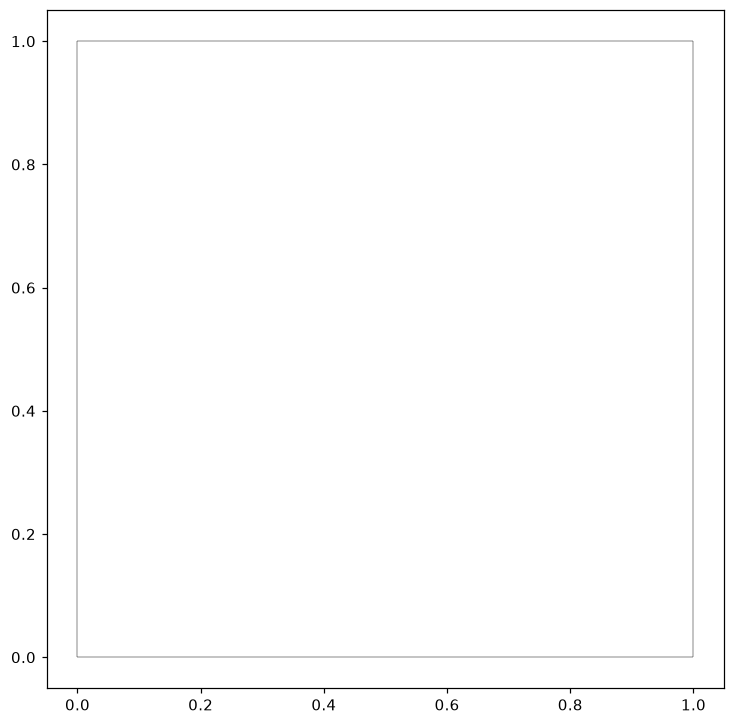

In [8]:
ds.plot_outline()
show()

## 8. A filled map: projected cell area

These are engineering meshes with **no CRS and (usually) no field data**, so there is nothing physical to colour by out of the box. A useful derived quantity is the **projected 2-D area of each cell**, available as `mesh.face_areas`. We attach it as a face variable with `with_variable(...)` and let `plot(...)` draw a filled colour map.

With one unit quad lying in the plane, the map is a single cell of area 1.0 — trivial, but it confirms the area derivation and the colour pipeline work.

area  min/max: 1.0 1.0


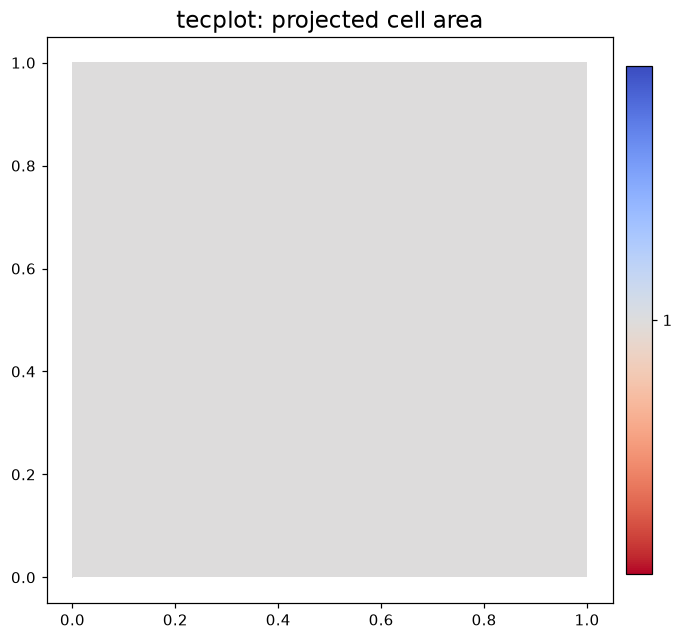

In [9]:
areas = np.asarray(ds.mesh.face_areas)
print("area  min/max:", float(areas.min()), float(areas.max()))
ds_area = ds.with_variable("cell_area", areas, location="face")
ds_area.plot("cell_area", cmap="viridis", colorbar=True,
             title="tecplot: projected cell area")
show()

## 9. The pyramids GIS toolbox applies

The payoff of turning a solver file into a `pyramids` object is that the whole GIS toolbox now works on it, even though this is a FEM/CFD mesh. Below we exercise several operations and interpret each result.

### Export to a GeoDataFrame

`to_geodataframe()` turns every cell into a `shapely` polygon inside a `geopandas` `GeoDataFrame` — the bridge to the entire vector-GIS ecosystem. Because the mesh has `crs=None`, the frame is unprojected (model units, not metres/degrees).

In [10]:
gdf = ds.to_geodataframe()
print("rows:", len(gdf), "| columns:", list(gdf.columns))
gdf.head()

rows:

 1 | columns: ['geometry']


,geometry
0,"POLYGON ((0 0, 1 0, 1 1, 0 1, 0 0))"


`geopandas` can draw it directly. This is the same geometry as the wireframe, now as first-class vector features.

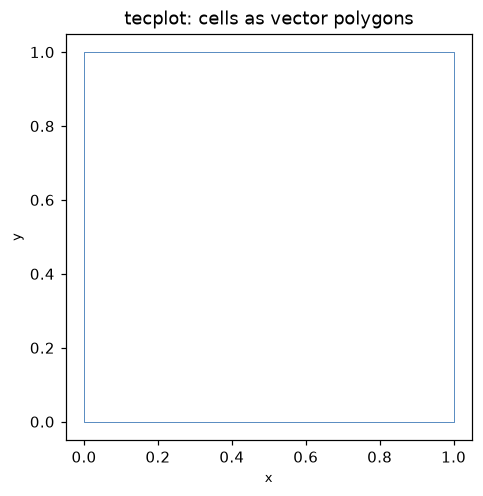

In [11]:
ax = gdf.plot(facecolor="none", edgecolor="#2b6cb0", linewidth=0.5)
ax.set_title("tecplot: cells as vector polygons")
ax.set_aspect("equal")
show()

### Dissolve to a bounding polygon

`bounding_polygon()` unions all cells into the single outer footprint of the mesh — useful as a clip mask or domain outline. We overlay it (red) on the grey cell edges.

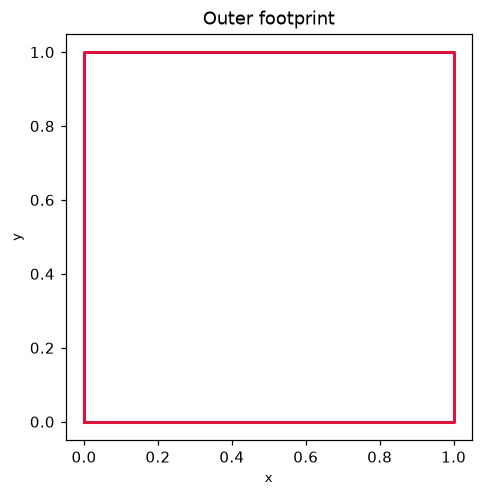

In [12]:
poly = ds.bounding_polygon()
ax = gdf.plot(facecolor="none", edgecolor="0.75", linewidth=0.4)
xs, ys = poly.exterior.xy
ax.plot(xs, ys, color="crimson", linewidth=2)
ax.set_aspect("equal")
ax.set_title("Outer footprint")
show()

### Boundary edges

`exterior_edges()` returns the indices of edges that belong to exactly one cell — the mesh boundary. A closed surface (a watertight solid) has none; an open sheet exposes its rim. We report the count.

In [13]:
edges = np.asarray(ds.exterior_edges())
print("boundary edges:", edges.size)

boundary edges: 4


### Face-adjacency as a sparse matrix

`sparse_adjacency()` returns the `(n_face, n_face)` SciPy CSR matrix of which cells share an edge — the connectivity graph solvers assemble their stencils from. We only report its shape and non-zero count.

In [14]:
A = ds.sparse_adjacency()
print("adjacency:", A.shape, "| non-zeros (directed edges):", A.nnz)

adjacency: (1, 1) | non-zeros (directed edges): 0


### Crop to a sub-region

`crop(bbox=(xmin, ymin, xmax, ymax))` keeps only the cells inside a window — the mesh equivalent of a spatial subset. Here we take the left half of the domain and re-draw it.

kept 1 of 1 cells


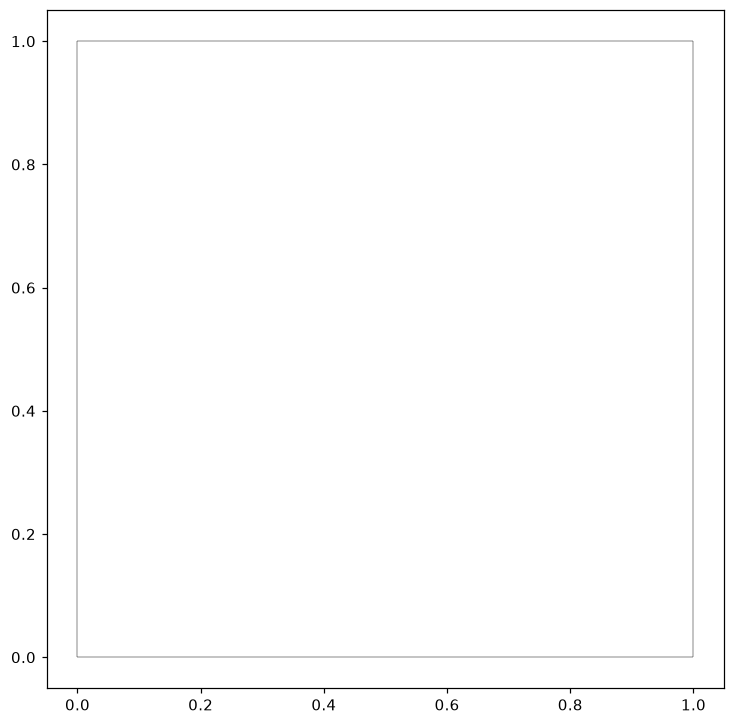

In [15]:
xmin, ymin, xmax, ymax = ds.bounds
sub = ds.crop(bbox=(xmin, ymin, (xmin + xmax) / 2, ymax))
if sub.n_face == 0:
    sub = ds  # degenerate window; fall back to the whole mesh
print("kept", sub.n_face, "of", ds.n_face, "cells")
sub.plot_outline()
show()

### Bridge to xarray

`to_xarray()` exposes the mesh and its variables as an `xarray.Dataset` (UGRID conventions) — the door to NetCDF I/O and the scientific-Python stack.

In [16]:
xds = ds.to_xarray()
print("dimensions:", dict(xds.sizes))
xds

dimensions: {'mesh2d_scalar': 1, 'mesh2d_nNodes': 4, 'mesh2d_nFaces': 1, 'mesh2d_nMaxFaceNodes': 4}


<xarray.Dataset> Size: 100B
Dimensions:            (mesh2d_scalar: 1, mesh2d_nNodes: 4, mesh2d_nFaces: 1,
                        mesh2d_nMaxFaceNodes: 4)
Dimensions without coordinates: mesh2d_scalar, mesh2d_nNodes, mesh2d_nFaces,
                                mesh2d_nMaxFaceNodes
Data variables:
    mesh2d             (mesh2d_scalar) int32 4B 0
    mesh2d_node_x      (mesh2d_nNodes) float64 32B 0.0 1.0 1.0 0.0
    mesh2d_node_y      (mesh2d_nNodes) float64 32B 0.0 0.0 1.0 1.0
    mesh2d_face_nodes  (mesh2d_nFaces, mesh2d_nMaxFaceNodes) int64 32B 1 2 3 4
Attributes:
    Conventions:  CF-1.8 UGRID-1.0

### What we skip, and why

Because this mesh carries **`crs=None`**, the reprojection and raster-bridge operations do not apply:

- `to_crs(...)` needs a source CRS to reproject *from* — skipped (there is no datum to interpret the model's bare coordinates).
- `rasterize_like(...)` / `regrid(...)` burn a mesh onto, or resample it against, a georeferenced raster grid — skipped here, as there is no spatial reference to align to.

These are first-class `pyramids` operations; they simply require a georeferenced mesh, which an engineering solver file is not.

## Takeaway

We read a minimal Tecplot FE zone (4 nodes, 1 quad), saw that an empty `summary()` is the right answer for a field-less mesh, and still ran GIS on it: vector export, footprint, its 4 boundary edges, the adjacency matrix, a crop, and an xarray bridge. Circumcenters are skipped — they are defined for triangles only.

The pattern is always the same: **`UgridDataset.read_file(path, driver=...)` turns a solver file into a `pyramids` object, and from there the full GIS toolbox applies** — even for a geometry-only, CRS-less engineering mesh. `pyramids-mesh` contributes only the driver; every mesh operation lives upstream in `pyramids`.